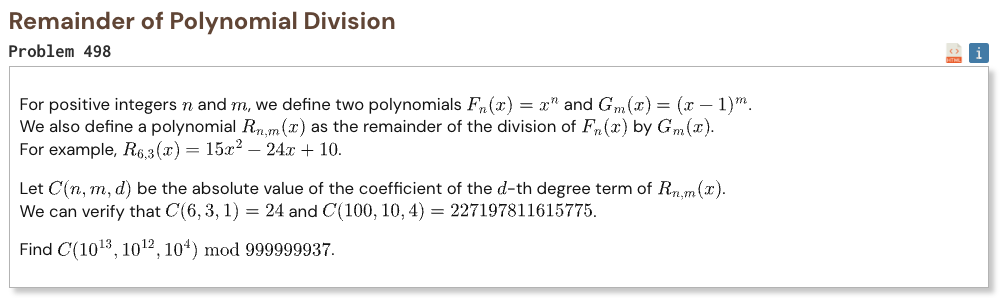

## Initial approach

- view the remainder as the truncated expansion of the original polynomial around one
- extract only the coefficient of the requested degree instead of building the whole polynomial
- simplify the alternating coefficient sum into a product of two binomial coefficients
- this simplification also reproduces both example values from the problem
- the required binomial numbers are enormous, so calculating factorials directly is impossible
- use Lucas theorem to split each huge binomial coefficient into much smaller ones modulo the given prime
- after the split, the largest factorial needed is only about six hundred thousand
- multiply the small binomial results modulo the given prime

In [1]:
%%time

MOD = 999999937
N = 10**13
M = 10**12
D = 10**4

def small_comb(n, k, mod):
    if k < 0 or k > n:
        return 0

    k = min(k, n - k)

    numerator = 1
    denominator = 1

    for i in range(1, k + 1):
        numerator = numerator * (n - k + i) % mod
        denominator = denominator * i % mod

    return numerator * pow(denominator, mod - 2, mod) % mod

def lucas(n, k, mod):
    result = 1

    while n > 0 or k > 0:
        ni = n % mod
        ki = k % mod

        if ki > ni:
            return 0

        result = result * small_comb(ni, ki, mod) % mod

        n //= mod
        k //= mod

    return result

part1 = lucas(N, D, MOD)
part2 = lucas(N - D - 1, M - D - 1, MOD)

result = part1 * part2 % MOD

print("Result:", result)

Result: 472294837
CPU times: user 8.37 ms, sys: 286 μs, total: 8.66 ms
Wall time: 8.92 ms
